<a href="https://colab.research.google.com/github/Sattvikannadatha/LLM-Ticket/blob/main/Internship_Task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ortools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 46.5 MB/s  0:00:00


In [2]:
# Step 1: Upload and Load the Dataset
from google.colab import files
import pandas as pd
import io

# 1. Prompts you to upload the file from your system
print("Click the 'Choose Files' button below to upload price_data.csv:")
uploaded = files.upload()

# 2. Get the exact name of the file you just uploaded
file_name = list(uploaded.keys())[0]

# 3. Read the CSV data into a Pandas DataFrame
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# 4. Convert the date column to actual datetime objects immediately
df['date'] = pd.to_datetime(df['date'])

# 5. Set the date as the index (required for time-series forecasting)
df.set_index('date', inplace=True)

# Display the first 5 rows to confirm it worked
df.head()

Click the 'Choose Files' button below to upload price_data.csv:


Saving price_data.csv to price_data.csv


,avg_monthly_price
date,
2005-01-01,5500
2005-02-01,5476
2005-03-01,5466
2005-04-01,5487
2005-05-01,5876


--- Missing Values Check ---
avg_monthly_price    0
dtype: int64

--- Outliers Detected: 7 ---
            avg_monthly_price
date                         
2023-12-01              16163
2024-04-01              15863
2024-05-01              15863
2024-06-01              15488
2024-07-01              15294
2025-07-01              16000
2025-09-01              15750


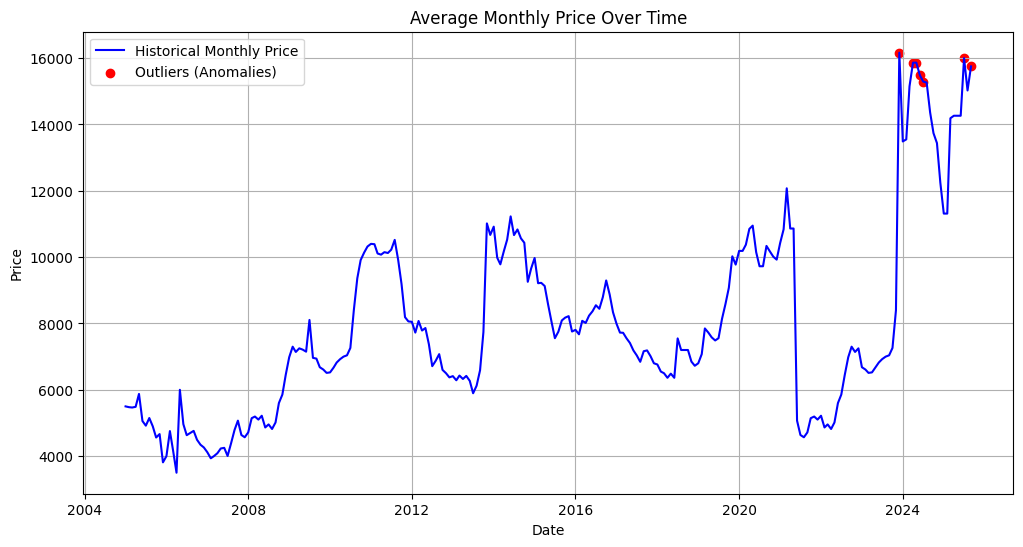

In [3]:
import matplotlib.pyplot as plt

# 1. Check for missing values
print("--- Missing Values Check ---")
print(df.isnull().sum())

# 2. Anomaly & Outlier Detection (using IQR method)
Q1 = df['avg_monthly_price'].quantile(0.25)
Q3 = df['avg_monthly_price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['avg_monthly_price'] < lower_bound) | (df['avg_monthly_price'] > upper_bound)]
print(f"\n--- Outliers Detected: {len(outliers)} ---")
if len(outliers) > 0:
    print(outliers)

# 3. Plotting the historical data to visualize trends and anomalies
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['avg_monthly_price'], label='Historical Monthly Price', color='blue')
if len(outliers) > 0:
    plt.scatter(outliers.index, outliers['avg_monthly_price'], color='red', label='Outliers (Anomalies)')
plt.title('Average Monthly Price Over Time')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

Training SARIMA Model... This might take a few seconds.
--- Model Evaluation (Test Data) ---
Mean Absolute Error (MAE): 1565.35
Root Mean Squared Error (RMSE): 1956.45

Generating Future 12-Month Forecast...


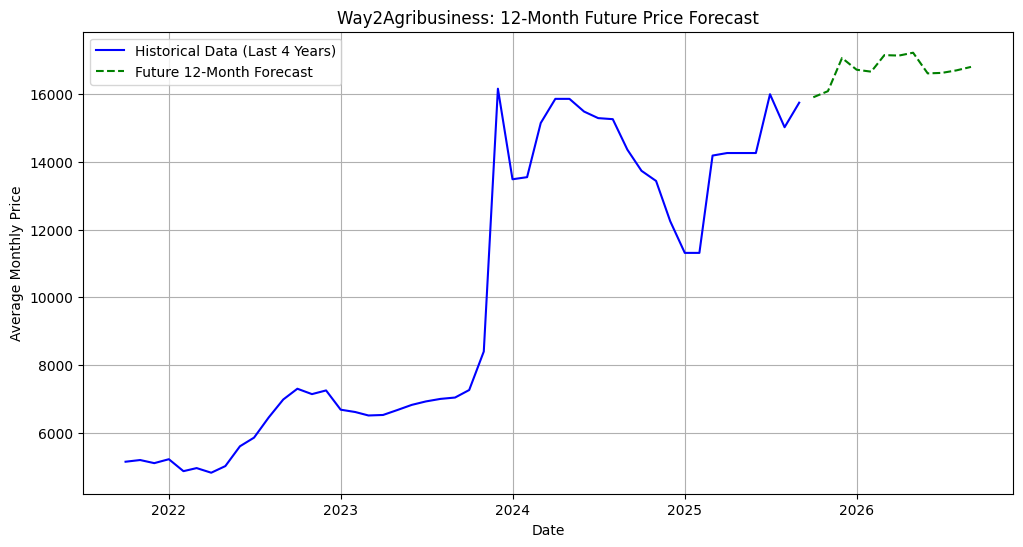

--- Predicted Prices for Next 12 Months ---
2025-10-01    15910.23
2025-11-01    16089.70
2025-12-01    17069.90
2026-01-01    16723.70
2026-02-01    16665.98
2026-03-01    17155.29
2026-04-01    17141.85
2026-05-01    17225.96
2026-06-01    16615.75
2026-07-01    16629.92
2026-08-01    16704.31
2026-09-01    16807.17
Freq: MS, Name: predicted_mean, dtype: float64


In [4]:
# Step 3: Train SARIMA Model and Forecast Future Prices
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# 1. Split data into training and testing (hold out last 12 months for testing)
train = df.iloc[:-12]
test = df.iloc[-12:]

# 2. Define and fit the SARIMA model
# (using order 1,1,1 and seasonal 1,1,1,12 to capture yearly agricultural trends)
print("Training SARIMA Model... This might take a few seconds.")
model = SARIMAX(train['avg_monthly_price'],
                order=(1, 1, 1),
                seasonal_order=(1, 1, 1, 12),
                enforce_stationarity=False,
                enforce_invertibility=False)
fitted_model = model.fit(disp=False)

# 3. Evaluate the model on the test set
predictions = fitted_model.get_forecast(steps=12).predicted_mean
mae = mean_absolute_error(test['avg_monthly_price'], predictions)
rmse = np.sqrt(mean_squared_error(test['avg_monthly_price'], predictions))

print(f"--- Model Evaluation (Test Data) ---")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}\n")

# 4. Forecast the NEXT 12 months into the future (Main Business Requirement)
print("Generating Future 12-Month Forecast...")
final_model = SARIMAX(df['avg_monthly_price'],
                order=(1, 1, 1),
                seasonal_order=(1, 1, 1, 12),
                enforce_stationarity=False,
                enforce_invertibility=False)
final_fitted = final_model.fit(disp=False)

future_forecast = final_fitted.get_forecast(steps=12)
future_mean = future_forecast.predicted_mean

# 5. Plot the final forecast
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(df.index[-48:], df['avg_monthly_price'][-48:], label='Historical Data (Last 4 Years)', color='blue')
plt.plot(future_mean.index, future_mean, label='Future 12-Month Forecast', color='green', linestyle='--')
plt.title('Way2Agribusiness: 12-Month Future Price Forecast')
plt.xlabel('Date')
plt.ylabel('Average Monthly Price')
plt.legend()
plt.grid(True)
plt.show()

print("--- Predicted Prices for Next 12 Months ---")
print(future_mean.round(2))

### 4. Actions to Respond to Predicted Price Changes
Based on the SARIMA forecast, prices are expected to remain high (above 15,000) and peak slightly in March/April 2026.
*   **Procurement Strategy:** Advance purchase of raw materials or secure long-term fixed-price contracts with suppliers immediately to lock in rates before the forecasted peak in Q1 2026.
*   **Inventory Management:** Increase warehousing and stockpiling to build a buffer.
*   **Pricing Optimization:** Gradually adjust end-customer pricing upward to protect profit margins as raw material costs remain elevated.

### 5. Determining Effectiveness of Actions
To measure if the above actions were successful, the company should monitor:
1.  **Cost of Goods Sold (COGS) vs. Spot Market Rate:** Track actual procurement costs against the spot market price. Effective stockpiling should result in a COGS lower than the market price during the March 2026 peak.
2.  **Gross Profit Margins:** Ensure margin percentages remain stable despite raw material price fluctuations.
3.  **Forecast Accuracy (Continuous):** Monitor how closely real-world prices match these predictions using MAPE (Mean Absolute Percentage Error).

### 6. Deploying the Model via Django
1.  **Serialization:** Save the trained SARIMA model using `joblib` or `pickle` (e.g., `joblib.dump(final_fitted, 'sarima_model.pkl')`).
2.  **Django App Setup:** Create a dedicated Django app for machine learning (`python manage.py startapp ml_api`).
3.  **Model Loading:** Load the `.pkl` file into memory during Django startup (inside `apps.py`) so it isn't reloaded on every HTTP request.
4.  **Creating the View:** Write a Django view that accepts an HTTP request, runs `model.forecast(steps=12)`, and returns a `JsonResponse` containing the forecasted dates and prices.

### 7. Integrating Django & FastAPI for Real-Time Predictions
*   **Microservice Architecture:** Run Django as the core backend (managing users, historical data, ORM) and FastAPI as a separate microservice specifically for model inference, as FastAPI is optimized for high-concurrency, low-latency API serving.
*   **FastAPI Endpoint:** FastAPI loads the ML model and exposes an async `/predict` endpoint. When the frontend or Django requests a prediction, FastAPI handles the computation instantly and returns structured JSON using Pydantic models for data validation.

### 8. Frontend Integration (Next.js & React Native)
1.  **API Communication:** Use `axios` or the native `fetch` API in both Next.js (web) and React Native (mobile) to call the FastAPI prediction endpoints.
2.  **State Management:** Use React Hooks (`useState`, `useEffect`) to manage loading states when fetching predictions.
3.  **Data Visualization:** Once the JSON array of predicted prices is received, use `Chart.js` or `Recharts` in Next.js, and `react-native-chart-kit` in React Native to render interactive time-series line graphs.

### 9. Monitoring in Production (Performance & Drift)
1.  **Performance Tracking:** Store all model predictions in the database. As real monthly prices arrive, calculate continuous error metrics (MAE, RMSE) on a dashboard (e.g., using Grafana).
2.  **Handling Model Drift:** Agribusiness markets shift due to climate or trade policies. If the continuous error crosses a threshold (e.g., > 15%), it triggers an alert indicating model drift.
3.  **Model Updating:** Implement an automated pipeline (using Celery). Every month, as new actual prices are logged, the pipeline automatically re-fits the SARIMA model on the updated dataset, saves the new `.pkl` file, and reloads it into the FastAPI service.

Name: Sattvik
Phone number: 8904375958
email: annadathasattvik@gmail.com